In [1]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

csv_file = os.path.join(path, "amz_uk_price_prediction_dataset.csv")
df = pd.read_csv(csv_file)

Path to dataset files: /Users/camillascandola/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3


In [2]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
#Create a crosstab between the product category and the isBestSeller status

crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
#Are there categories where being a best-seller is more prevalent?

crosstab_result["total_items"] = crosstab_result[False] + crosstab_result[True]
crosstab_result

isBestSeller,False,True,total_items
category,,,
3D Printers,247,1,248
3D Printing & Scanning,4065,2,4067
Abrasive & Finishing Products,245,5,250
Action Cameras,1696,1,1697
Adapters,251,3,254
...,...,...,...
Wind Instruments,243,7,250
Window Treatments,234,5,239
Women,17559,213,17772


In [5]:
crosstab_result["best_seller_rate"] = crosstab_result[True] / crosstab_result["total_items"]
crosstab_result

isBestSeller,False,True,total_items,best_seller_rate
category,,,,
3D Printers,247,1,248,0.004032
3D Printing & Scanning,4065,2,4067,0.000492
Abrasive & Finishing Products,245,5,250,0.020000
Action Cameras,1696,1,1697,0.000589
Adapters,251,3,254,0.011811
...,...,...,...,...
Wind Instruments,243,7,250,0.028000
Window Treatments,234,5,239,0.020921
Women,17559,213,17772,0.011985


In [6]:
#Top 10 categories where best-sellers are more present

crosstab_result.sort_values("best_seller_rate", ascending=False).head(10)

isBestSeller,False,True,total_items,best_seller_rate
category,,,,
Grocery,9008,556,9564,0.058135
Smart Home Security & Lighting,98,6,104,0.057692
Health & Personal Care,9017,552,9569,0.057686
Mobile Phone Accessories,248,11,259,0.042471
Power & Hand Tools,8353,306,8659,0.035339
"Billiard, Snooker & Pool",241,8,249,0.032129
Pet Supplies,9152,285,9437,0.030200
Home Brewing & Wine Making,239,7,246,0.028455
Wind Instruments,243,7,250,0.028000


In [7]:
#Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category

from scipy.stats import chi2_contingency

# Chi-square test for 'isBestSeller category' and 'best_seller_rate'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36684.384144034884), np.float64(0.0))

The chi-square test shows a p-value near zero, indicating that best-seller status is not independent of product category.
In other words, some categories have significantly higher (or lower) proportions of best-seller items than would be expected by chance

In [8]:
crosstab_clean = crosstab_result.drop(columns=["total_items", "best_seller_rate"])
crosstab_clean.columns

Index([False, True], dtype='object', name='isBestSeller')

In [9]:
#Compute Cramér's V to understand the strength of association between best-seller status and category

from scipy.stats.contingency import association

association(crosstab_clean, method="cramer")

0.1222829439760564

The result suggests a weak association between the two variables

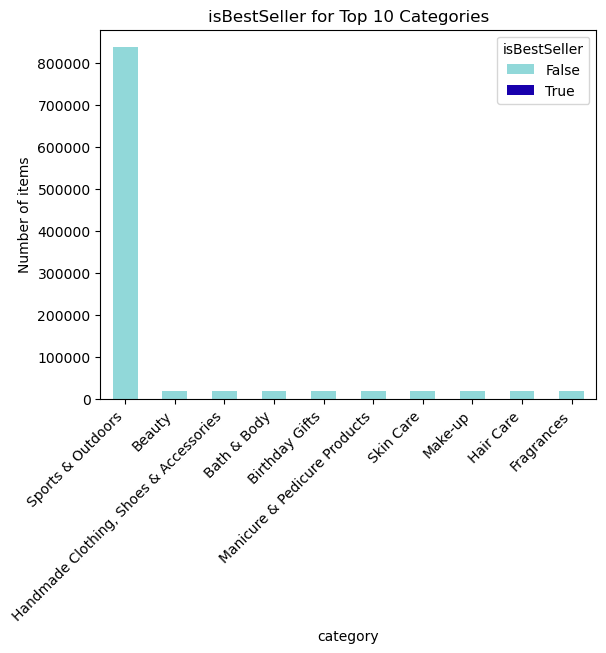

In [20]:
#Visualize the relationship between product categories and the best-seller status using a stacked bar chart

#creating a new table where category is a column
crosstab = pd.crosstab(df["category"], df["isBestSeller"])

#selecting just the top 10 categories
top10 = crosstab.sum(axis=1).sort_values(ascending=False).head(10).index
crosstab_top10 = crosstab.loc[top10]

#creating the stack bar chart
crosstab_top10.plot(kind="bar", stacked=True, color=["#91D8D9", "#1800AD"])
plt.ylabel("Number of items")
plt.title("isBestSeller for Top 10 Categories")
plt.xticks(rotation=45, ha="right")
plt.show()

In [11]:
#Remove outliers in product prices

#Calculating IQR
    
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
    
#Bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
    
#Identifying the outliers
outliers = df['price'][(df['price'] < lower_bound) | (df['price'] > upper_bound)]
    
outliers.count()

np.int64(327688)

In [12]:
#Removing the outliers
df_without_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

df_without_outliers.count()

uid                  2115963
asin                 2115963
title                2115963
stars                2115963
reviews              2115963
price                2115963
isBestSeller         2115963
boughtInLastMonth    2115963
category             2115963
dtype: int64

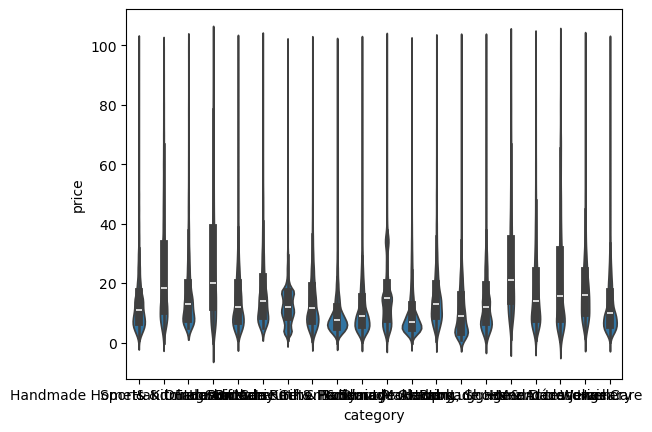

In [13]:
#Use a violin plot to visualize the distribution of price across different product categories
#Filter out the top 20 categories based on count for better visualization
import seaborn as sns
import matplotlib.pyplot as plt

#selecting just the top 20 categories
top20_categories = (df_without_outliers["category"].value_counts().head(20).index)

no_outliers_top20 = df_without_outliers[df_without_outliers["category"].isin(top20_categories)]

sns.violinplot(data=no_outliers_top20, x='category', y='price')
plt.show()

In [33]:
#Which product category tends to have the highest median price? Don't filter here by top categories
median_prices = df_without_outliers.groupby("category")["price"].median().sort_values(ascending=False)
median_prices.head(1)

category
Desktop PCs    74.0
Name: price, dtype: float64

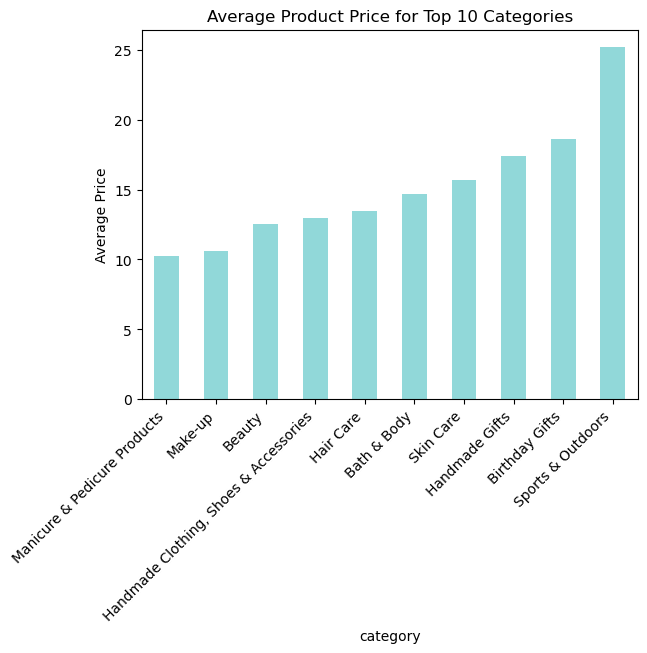

In [22]:
#Create a bar chart comparing the average price of products for the top 10 product categories (based on count)
import matplotlib.pyplot as plt

#top10 categories (without outliers)

top10_categories = (df_without_outliers["category"].value_counts().head(10).index)

no_outliers_top10 = df_without_outliers[df_without_outliers["category"].isin(top10_categories)]

#define average prices per category

avg_prices = no_outliers_top10.groupby("category")["price"].mean().sort_values()

#creating bar chart
avg_prices.plot(kind="bar", color="#91D8D9")
plt.ylabel("Average Price")
plt.title("Average Product Price for Top 10 Categories")
plt.xticks(rotation=45, ha="right")
plt.show()

In [34]:
#Which product category commands the highest average price? Don't filter here by top categories
avg_prices = df_without_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
avg_prices.head(1)

category
Motherboards    68.772432
Name: price, dtype: float64

/var/folders/mg/bhcm044157v8jjlw0q70h74w0000gn/T/ipykernel_39805/3058834505.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=no_outliers_top10, x='category', y='stars', palette="coolwarm")


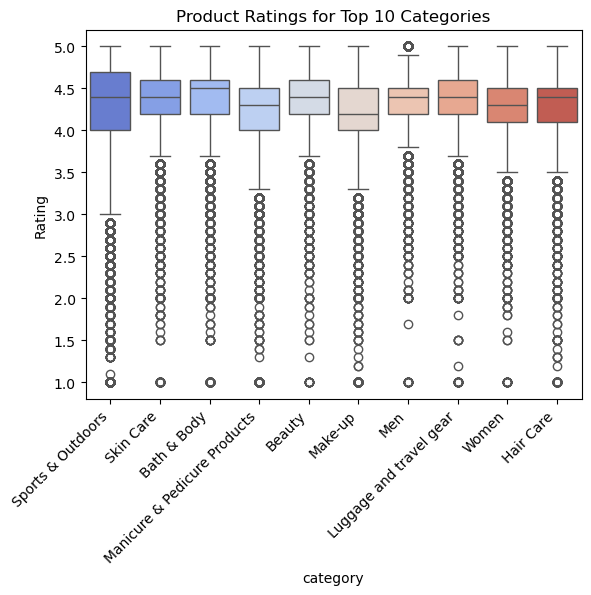

In [32]:
#Visualize the distribution of product ratings based on their category using side-by-side box plots
#Filter out the top 10 categories based on count for better visualization

#creating a new dataset and filtering out all nan values for stars and values equal to 0 
df_without_outliers_clean = df_without_outliers[df_without_outliers['stars'].notna() & (df_without_outliers['stars'] > 0)].copy()

top10_categories = (df_without_outliers_clean["category"].value_counts().head(10).index)

no_outliers_top10 = df_without_outliers_clean[df_without_outliers_clean["category"].isin(top10_categories)]

rating_distribution = no_outliers_top10.groupby("category")["stars"]

sns.boxplot(data=no_outliers_top10, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Rating")
plt.title("Product Ratings for Top 10 Categories")
plt.show()

In [44]:
#Which category tends to receive the highest median rating from customers? Don't filter here by top categories
median_prices = df_without_outliers_clean.groupby("category")["stars"].median().sort_values(ascending=False)
median_prices.head(1)

category
Made in Italy Handmade    5.0
Name: stars, dtype: float64

In [42]:
#Calculate the correlation coefficient between price and stars
correlation = df_without_outliers_clean['price'].corr(df_without_outliers['stars'])
correlation

np.float64(0.006744508067157982)

Product price and customer star ratings are unrelated; more expensive items do not tend to get higher or lower ratings

<Axes: xlabel='stars', ylabel='price'>

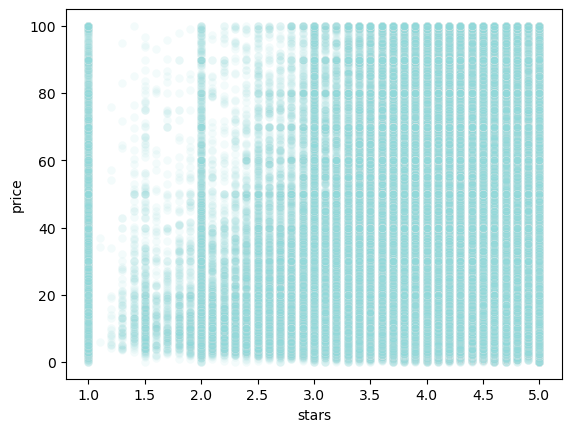

In [45]:
#Use a scatter plot to visualize the relationship between product rating and price
#What patterns can you observe?
sns.scatterplot(data=df_without_outliers_clean, x="stars", y="price",alpha=0.1, color='#91D8D9')

Mid-rated products (between 1 and 2 stars) are relatively rare compared to highly-rated products (between 4 and 5 stars). Most items tend to receive high ratings

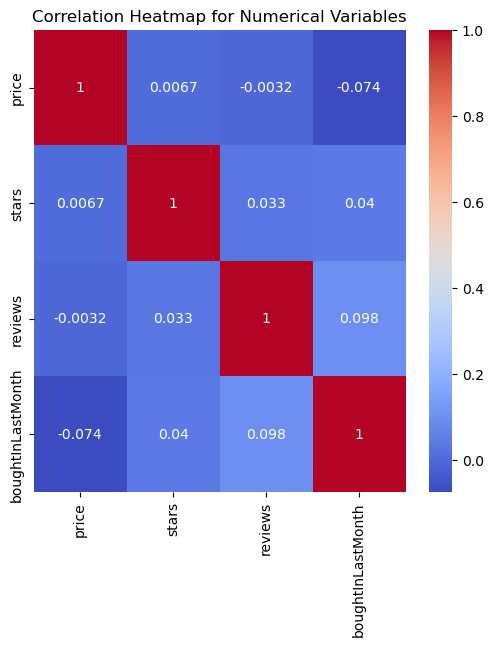

In [53]:
# Select only numerical columns
numeric_df = df_without_outliers_clean[['price', 'stars', 'reviews', 'boughtInLastMonth']]

# Compute the correlation matrix
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(6,6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap for Numerical Variables")
plt.show()

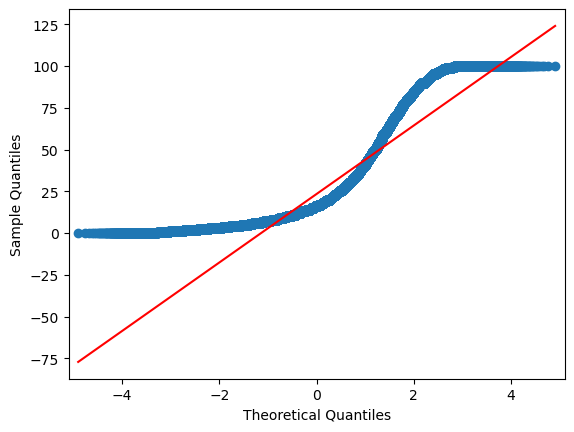

In [54]:
import statsmodels.api as sm

#Q-Q plot for prices to check if its distribution follows a normal distribution
sm.qqplot(df_without_outliers['price'], line='s');

The Q–Q plot shows that product prices deviate from a normal distribution, showing a heavy right skew with many low-cost items and a small number of much higher-priced products